# Лабораторная работа №1

## Задания

![Задания](./tasks.png "Задания")

## Библиотеки

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error

## Реализация

### Загрузка данных

In [2]:
df = pd.read_csv("series.csv", parse_dates=["timestamp"])
df.head()

,timestamp,value
0,2026-11-18 00:00:00,101.995074
1,2026-11-18 01:00:00,94.934438
2,2026-11-18 02:00:00,96.359036
3,2026-11-18 03:00:00,69.061720
4,2026-11-18 04:00:00,NaN


### Сортировка и проверка дубликатов

In [3]:
df = df.sort_values("timestamp").drop_duplicates("timestamp").set_index("timestamp")
df.head()

,value
timestamp,
2026-11-18 00:00:00,101.995074
2026-11-18 01:00:00,94.934438
2026-11-18 02:00:00,96.359036
2026-11-18 03:00:00,69.061720
2026-11-18 04:00:00,NaN


### Установка временного индекса и проверка частоты

In [4]:
full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
df = df.reindex(full_idx)
df.index.name = "timestamp"
df.head()

,value
timestamp,
2026-11-18 00:00:00,101.995074
2026-11-18 01:00:00,94.934438
2026-11-18 02:00:00,96.359036
2026-11-18 03:00:00,69.061720
2026-11-18 04:00:00,NaN


### Скользящее среднее и скользящее стандартное отклонение

In [5]:
df["rolling_mean"] = df["value"].rolling(24).mean()
df["rolling_std"] = df["value"].rolling(24).std()
df.head()

,value,rolling_mean,rolling_std
timestamp,,,
2026-11-18 00:00:00,101.995074,NaN,NaN
2026-11-18 01:00:00,94.934438,NaN,NaN
2026-11-18 02:00:00,96.359036,NaN,NaN
2026-11-18 03:00:00,69.061720,NaN,NaN
2026-11-18 04:00:00,NaN,NaN,NaN


### График всего ряда со скользящим средним

In [6]:
def plot_with_mean(df):
    plt.figure(figsize=(12, 4))
    plt.plot(df.index, df["value"], label="y")
    plt.plot(df.index, df["rolling_mean"], label="rolling mean")
    plt.legend()
    plt.show()

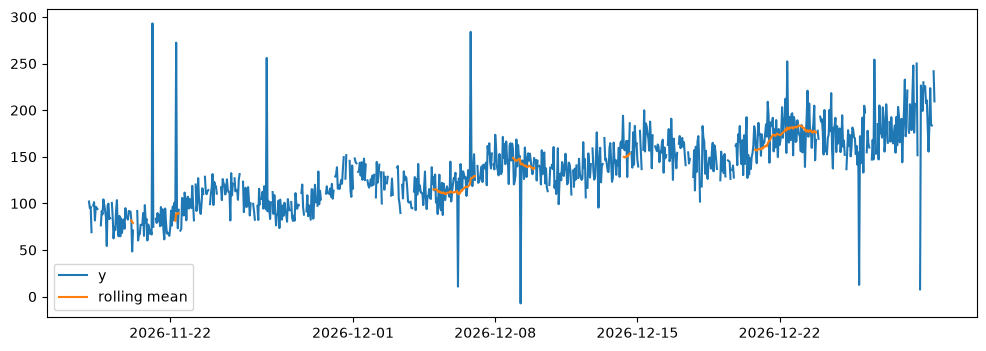

In [7]:
plot_with_mean(df)

### График скользящего стандартного отклонения

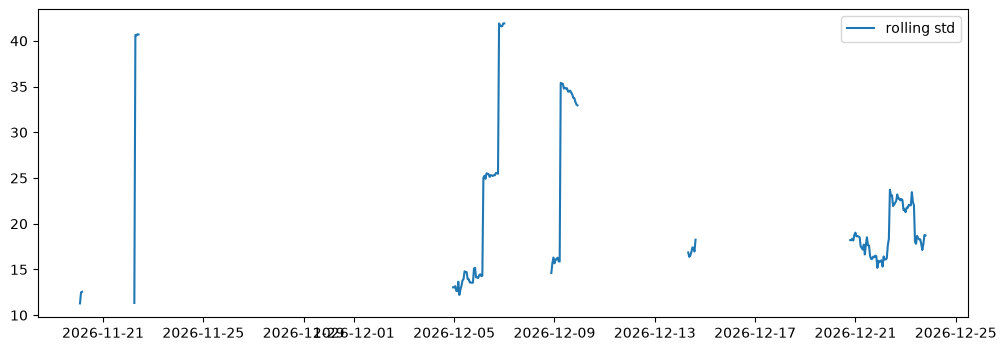

In [8]:
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["rolling_std"], label="rolling std")
plt.legend()
plt.show()

### Отдельный фрагмент

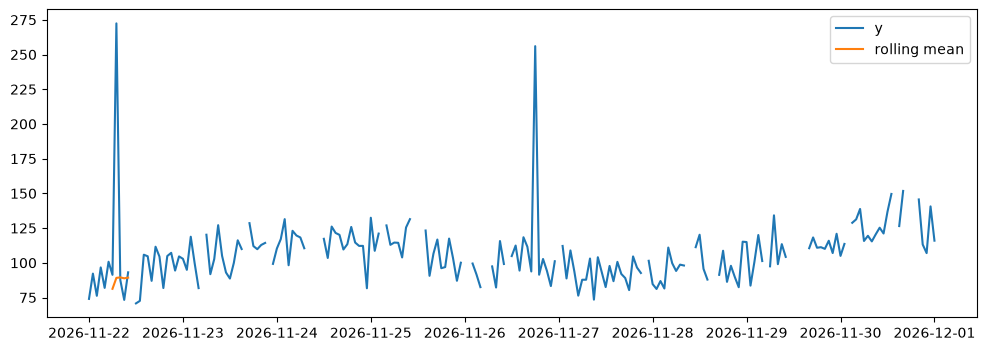

In [9]:
fragment = pd.date_range("2026-11-22", "2026-12-01", freq="h")
plot_with_mean(df.loc[fragment])

### Сезонные подсерии

По заданию сезонность длится 7 дней, будет 7 подсерий по одной для каждого дня недели, внутри каждой подсерии - 24 часа

In [10]:
df['day_of_week'] = df.index.day_of_week  # 0 - понедельник, 1 - вторник и т.д.
df['hour'] = df.index.hour

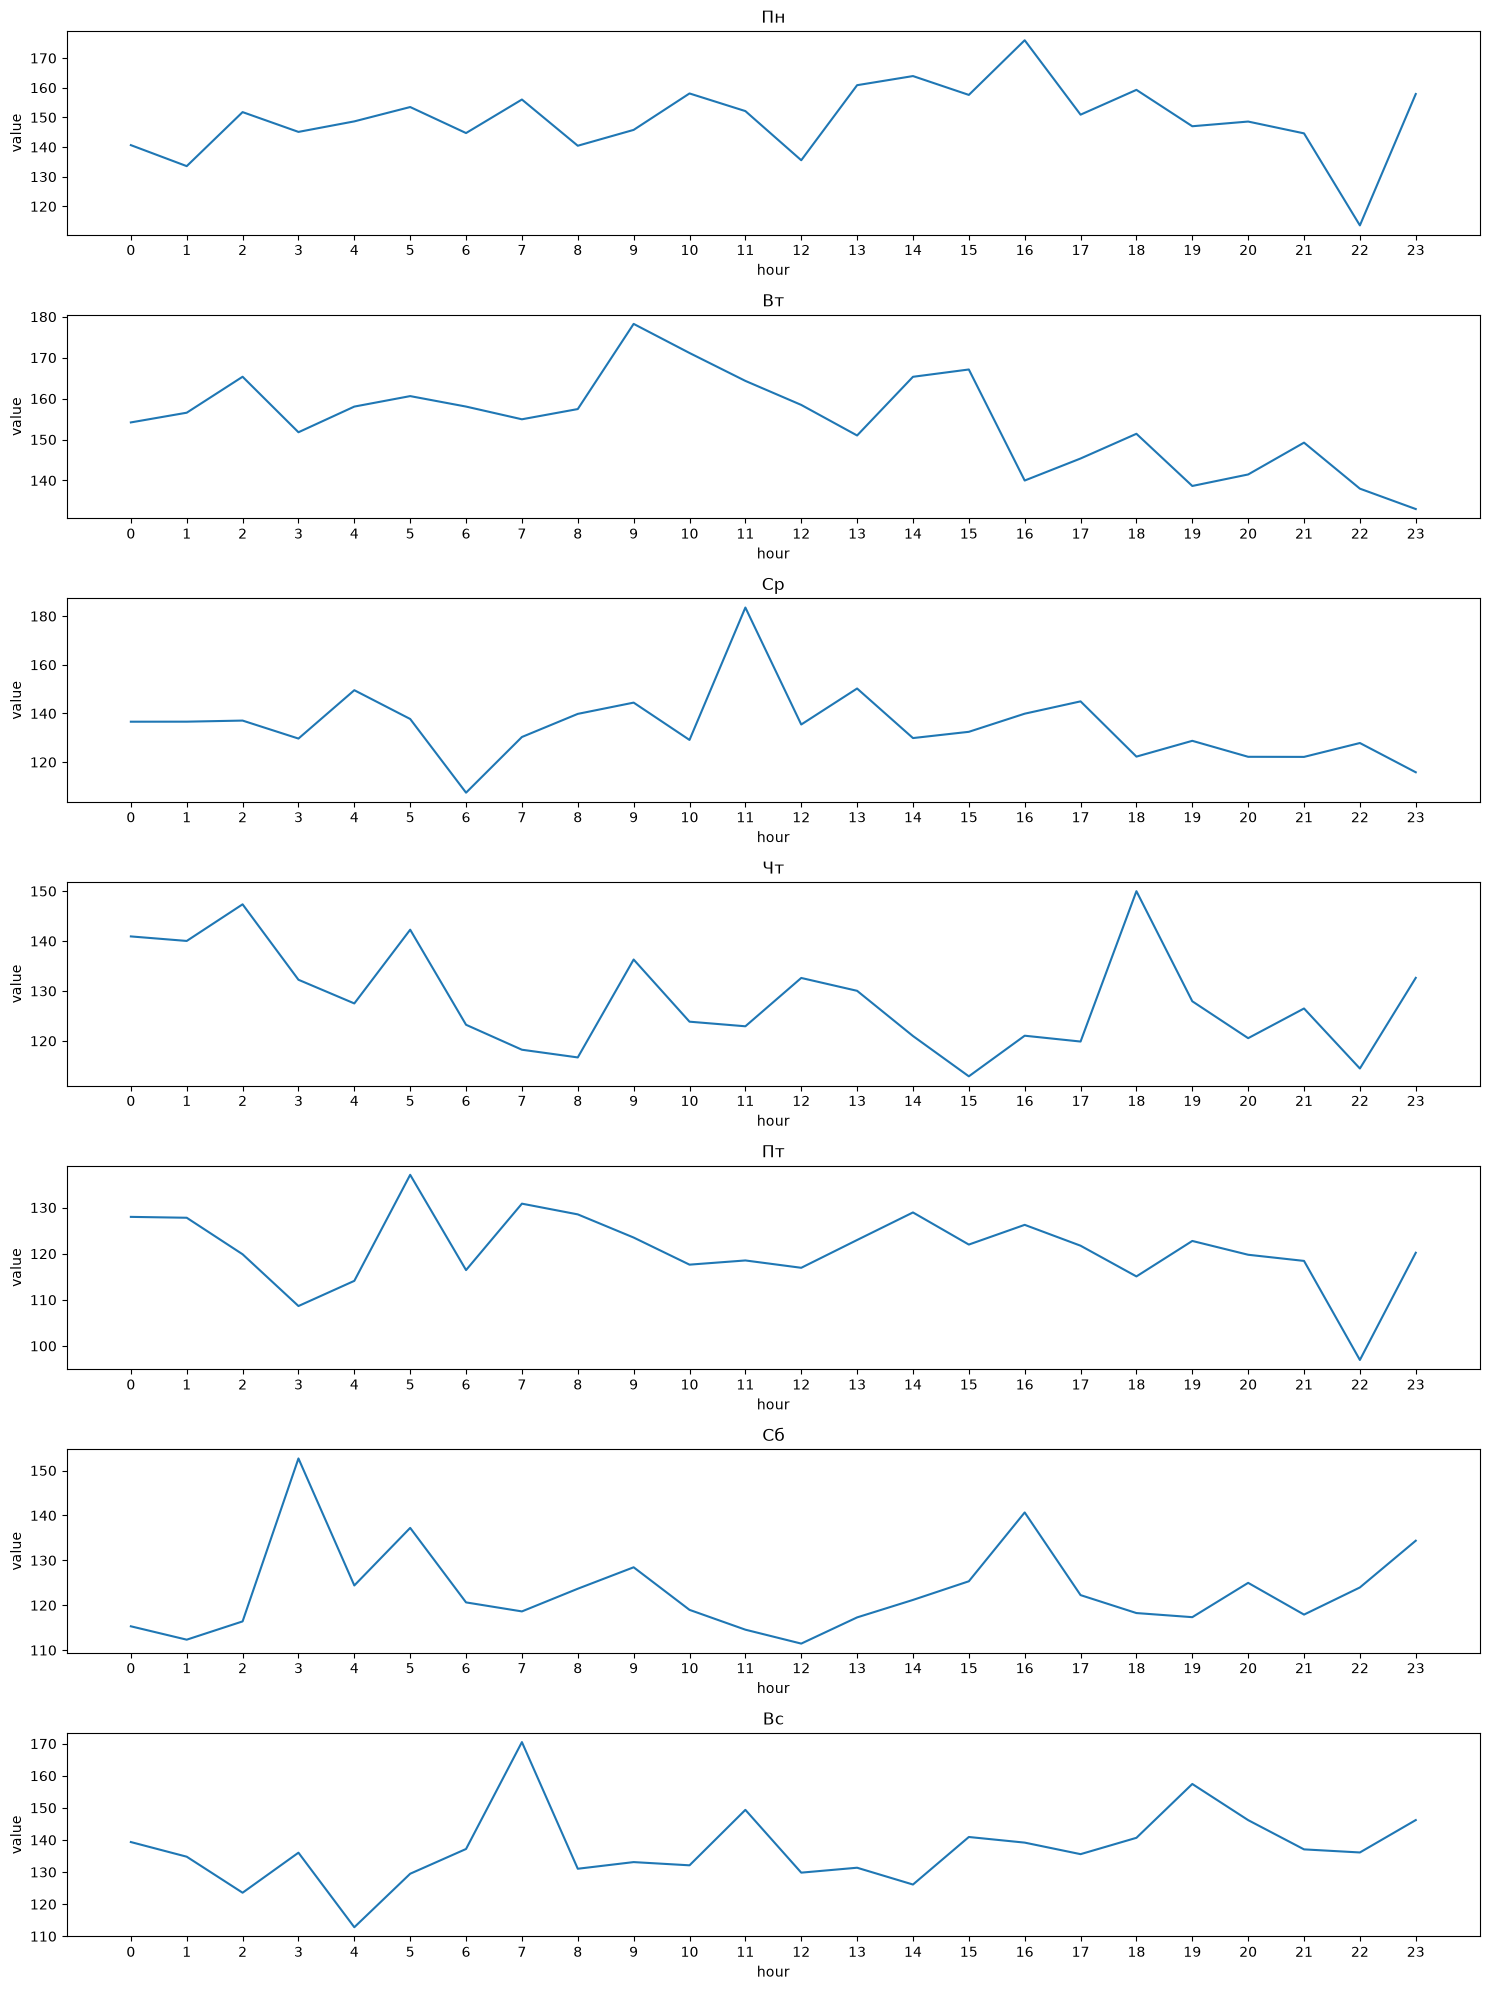

In [11]:
fig, axes = plt.subplots(7, 1, figsize=(15, 20))

for day, ax in enumerate(axes):
    subset = df[df['day_of_week'] == day]

    sns.lineplot(data=subset, x='hour', y='value', ax=ax, errorbar=None)

    ax.set_title(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'][day])  # чтобы было понятнее

    ax.set_xticks(range(24))

plt.tight_layout()
plt.show()

### Тепловая карта "час x день недели"

In [12]:
heatmap_data = df.pivot_table(index='hour', columns='day_of_week', values='value', aggfunc='mean')

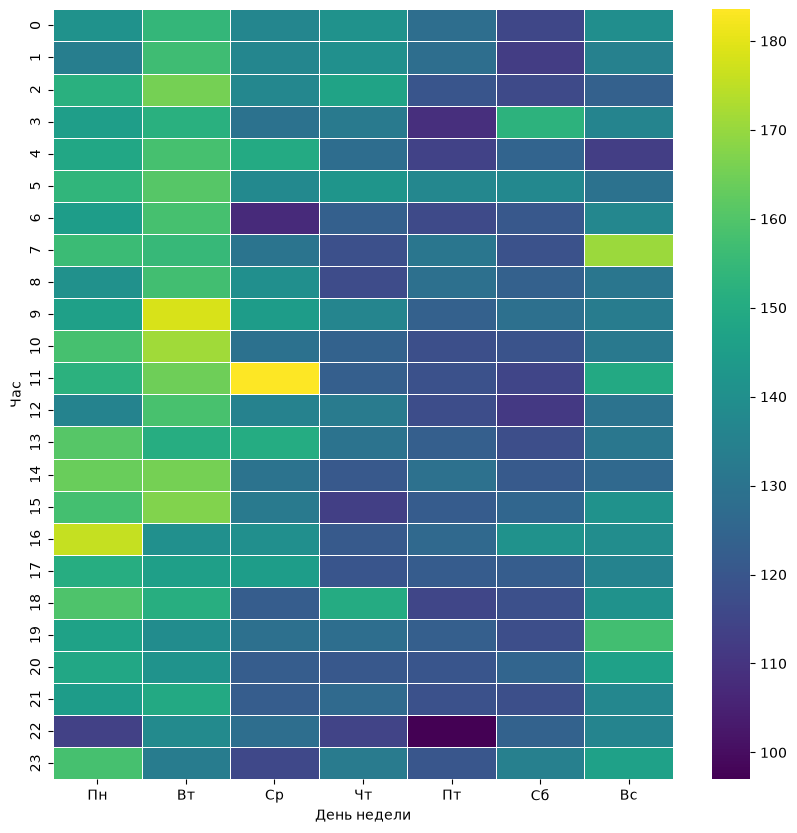

In [13]:
plt.figure(figsize=(10, 10))

sns.heatmap(heatmap_data, cmap='viridis', annot=False, linewidths=0.5)

plt.xlabel('День недели')
plt.ylabel('Час')

plt.xticks(ticks=np.arange(7) + 0.5, labels=['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])

plt.show()

### Пропуски

In [14]:
df_gaps = df["value"].isna()

#### Количество

In [15]:
print(df_gaps.sum())

100


#### Где они

In [16]:
df.loc[df_gaps]

,value,rolling_mean,rolling_std,day_of_week,hour
timestamp,,,,,
2026-11-18 04:00:00,NaN,NaN,NaN,2,4
2026-11-18 11:00:00,NaN,NaN,NaN,2,11
2026-11-18 13:00:00,NaN,NaN,NaN,2,13
2026-11-19 02:00:00,NaN,NaN,NaN,3,2
2026-11-20 05:00:00,NaN,NaN,NaN,4,5
...,...,...,...,...,...
2026-12-28 17:00:00,NaN,NaN,NaN,0,17
2026-12-28 20:00:00,NaN,NaN,NaN,0,20
2026-12-28 21:00:00,NaN,NaN,NaN,0,21


#### Самая длинная последовательность пропусков

Пояснение:

* `~` даёт отрицание
* `cumsum()` суммирует кумулятивно, если предыдущее и последующее значение одинаковы, тогда это последовательность
* `[df_gaps]` маска по последовательности с исходным DataFrame
* `value_counts()` считаем длину последовательностей
* `max()` возвращаем максимум

In [17]:
print((~df_gaps).cumsum()[df_gaps].value_counts().max())

3


### Импутация

#### Через ffill (берём предыдущее значение)

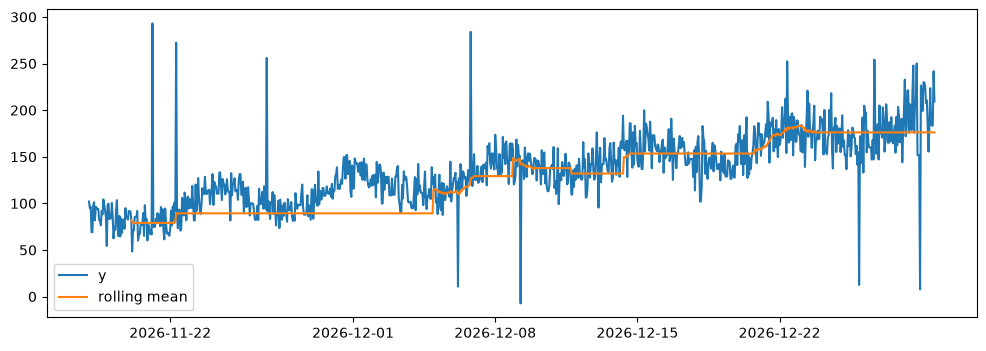

In [18]:
df_ffill = df.ffill()
plot_with_mean(df_ffill)

#### Линейная интерполяция

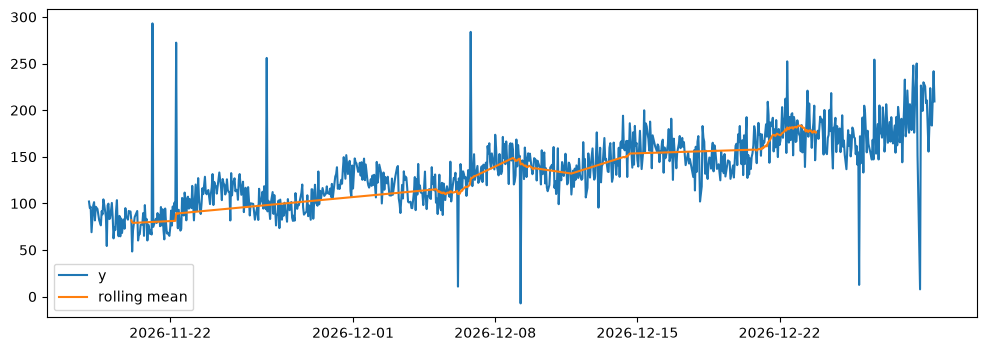

In [19]:
df_lin = df.interpolate(method="linear", limit_area="inside")  # хотя в качестве метода лучше "time"
plot_with_mean(df_lin)

#### Медиана

Я так понимаю, имелась ввиду сезонная медиана, т.к. она лучше подходит для этой задачи, чем просто заполнить всё одним значением

Поиск выбросов через IQR

In [20]:
q1, q3 = df["value"].quantile([0.25, 0.75])
iqr = q3 - q1
df["outlier_iqr"] = (df["value"] < q1 - 1.5 * iqr) | (df["value"] > q3 + 1.5 * iqr)
df.head()

,value,rolling_mean,rolling_std,day_of_week,hour,outlier_iqr
timestamp,,,,,,
2026-11-18 00:00:00,101.995074,NaN,NaN,2,0,False
2026-11-18 01:00:00,94.934438,NaN,NaN,2,1,False
2026-11-18 02:00:00,96.359036,NaN,NaN,2,2,False
2026-11-18 03:00:00,69.061720,NaN,NaN,2,3,False
2026-11-18 04:00:00,NaN,NaN,NaN,2,4,False
